# Building a Silicon supercell

This notebook builds a block of Silicon's atomic structure, a **supercell**, with pyEMAPS, step
by step. It follows the *si_constructor.py* sample, one step per cell.

You'll:

1. build a supercell from Silicon's unit cell;
2. check it against what you know about Silicon: the number of atoms, the bonds and the density;
3. draw it, and view it along the [110] direction, as an electron microscope does;
4. save it for other programs.

**The diamond structure in brief.** A crystal's data gives its unit cell, its space group and
the atoms of the **asymmetric unit**; the space group's symmetry operations generate the rest.
Silicon has the diamond structure: a face-centred cubic lattice with two atoms per lattice
point, a quarter of the cube diagonal apart. That makes 8 atoms per cubic cell, each bonded to 4
neighbours at the corners of a tetrahedron, at a distance

$$d = \frac{\sqrt{3}}{4}\,a$$

where $a$ is the cell constant. A supercell repeats the unit cell in each direction. Atomic
models like this are the starting point for image simulations, for visualization, and for
building defects and interfaces.

**Requirements.** pyEMAPS on Windows, with Python 3.12 to 3.15, and Jupyter in the same
environment:

```
pip install pyemaps jupyter
```

## Step 1: Import pyEMAPS and load the crystal

Silicon's data has one atom: the asymmetric unit. Its position, (0.125, 0.125, 0.125) in cell
fractions, is for the second origin choice of space group 227, *Fd*-3*m*, the setting printed in
the last line.

In [1]:
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np

from pyemaps import Crystal

print('pyEMAPS', version('pyemaps'))

silicon = Crystal.from_builtin('Silicon')
print(silicon)

pyEMAPS 2.1.1.dev11
Crystal name: Silicon dw iso
cell: 5.4307 5.4307 5.4307 90.0 90.0 90.0
SI 0.125 0.125 0.125 0.4668 1.00
spg: 227 2


## Step 2: Build the supercell

`generateMxtal` builds the block. By default it fills 3 × 3 × 3 unit cells (`cellbox`), with the
crystal's [100] and [001] directions along the block's x and z axes (`xz`). It returns the atoms
in the XYZ format that many structure viewers read: the number of atoms, a line with the box,
then one line per atom with its element and its x, y and z position in Å. These are the first
five lines:

In [2]:
supercell = silicon.generateMxtal()

text = str(supercell).splitlines()
print('\n'.join(text[:5]))
print('...')

216
	 50.0 50.0 50.0 90.0 90.0 90.0
SI        	0.678837418600 0.678837478200 0.678837478200
SI        	3.394187212000 3.394187450400 0.678837359000
SI        	4.751862525900 2.036512374900 2.036512374900
...


To work with the atoms, read the positions into a NumPy array:

In [3]:
def positions(xtal):
    """The atom positions of a generateMxtal block, in Å, as an n x 3 array."""
    lines = str(xtal).splitlines()
    n = int(lines[0])
    return np.array([[float(v) for v in line.split()[1:4]] for line in lines[2:2 + n]])


xyz = positions(supercell)
print(len(xyz), 'atoms; x, y and z from', xyz.min(axis=0).round(3), 'to', xyz.max(axis=0).round(3), 'Å')

216 atoms; x, y and z from [0.679 0.679 0.679] to [15.613 15.613 15.613] Å


## Step 3: Check it

A 3 × 3 × 3 block of a cell with 8 atoms holds 216 atoms. Next, the bonds: the distances from an
atom in the middle of the block to its nearest neighbours, and the angles between those bonds.

In [4]:
a = silicon.cell.a

distances = np.linalg.norm(xyz[:, None] - xyz[None], axis=-1)      # every pair of atoms
middle = np.argmin(np.linalg.norm(xyz - xyz.mean(axis=0), axis=1))
neighbours = np.where((distances[middle] > 0) & (distances[middle] < 2.5))[0]
bonds = xyz[neighbours] - xyz[middle]

print(f'{len(neighbours)} nearest neighbours at', distances[middle, neighbours].round(4), 'Å')
print(f'sqrt(3)/4 a = {np.sqrt(3) / 4 * a:.4f} Å')

angles = [np.degrees(np.arccos(np.dot(u, v) / np.linalg.norm(u) / np.linalg.norm(v)))
          for i, u in enumerate(bonds) for v in bonds[i + 1:]]
print('Bond angles:', np.round(angles, 2), '°')
print(f'Tetrahedral angle, arccos(-1/3) = {np.degrees(np.arccos(-1 / 3)):.2f}°')

4 nearest neighbours at [2.3516 2.3516 2.3516 2.3516] Å
sqrt(3)/4 a = 2.3516 Å
Bond angles: [109.47 109.47 109.47 109.47 109.47 109.47] °
Tetrahedral angle, arccos(-1/3) = 109.47°


Four neighbours at $\sqrt{3}a/4$ = 2.35 Å, with every bond angle at the tetrahedral
109.47°. The density follows from the cell too: 8 atoms of 28.0855 u in a cube of side $a$.

In [5]:
AMU = 1.66053907e-24                          # g
density = 8 * 28.0855 * AMU / (a * 1e-8) ** 3   # a in cm
print(f'Density: {density:.3f} g/cm³')

Density: 2.329 g/cm³


That's Silicon's measured density, 2.33 g/cm³.

## Step 4: Draw it

A 3D plot of the atoms, with a line for each bond:

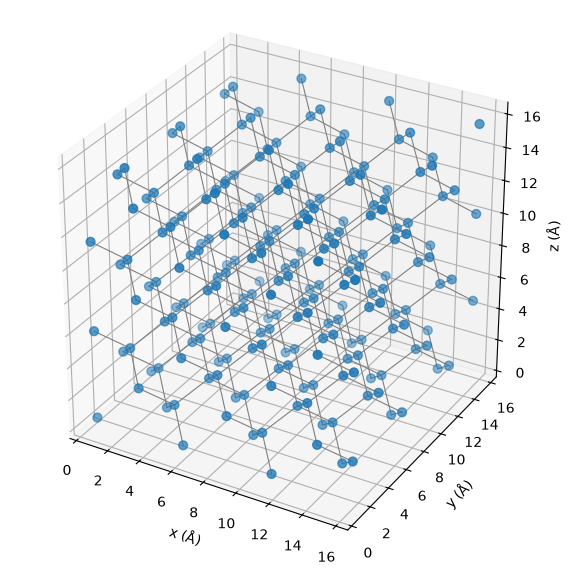

In [6]:
fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(projection='3d')

i, j = np.where(np.triu((distances > 0) & (distances < 2.5)))
for p, q in zip(i, j):
    ax.plot(*zip(xyz[p], xyz[q]), color='grey', linewidth=0.8)
ax.scatter(*xyz.T, s=40, color='tab:blue', depthshade=True)

ax.set_xlabel('x (Å)')
ax.set_ylabel('y (Å)')
ax.set_zlabel('z (Å)')
ax.set_box_aspect((1, 1, 1))
plt.show()

## Step 5: View it along [110]

An electron microscope sees a crystal in projection, along the beam. `xz` turns the block: here
it puts the crystal's [001] direction along x and [110] along z, so looking down z is looking
down [110]. In this projection, Silicon's atoms line up in columns that come in close pairs, the
**dumbbells** seen in atomic-resolution images. The pairs are $a/4$ apart.

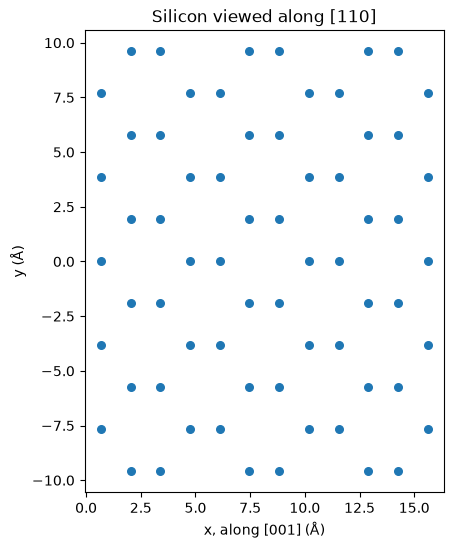

Closest columns: 1.357 Å apart; a/4 = 1.358 Å


In [7]:
oriented = positions(silicon.generateMxtal(xz=[[0, 0, 1], [1, 1, 0]]))
columns = np.unique(oriented[:, :2].round(3), axis=0)       # the projected atom columns

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(*columns.T, s=30)
ax.set_aspect('equal')
ax.set_xlabel('x, along [001] (Å)')
ax.set_ylabel('y (Å)')
ax.set_title('Silicon viewed along [110]')
plt.show()

gaps = np.linalg.norm(columns[:, None] - columns[None], axis=-1)
print(f'Closest columns: {gaps[gaps > 0].min():.3f} Å apart; a/4 = {a / 4:.3f} Å')

## Step 6: Save it

`writeXYZ` saves the block as an `.xyz` file, in the `mxtal` folder of the pyEMAPS data folder:
the folder named by the `PYEMAPS_DATA` environment variable, or the current folder if it isn't
set. Structure viewers such as [Jmol](https://jmol.sourceforge.net/) can open it.

In [8]:
silicon.writeXYZ(supercell)

Successfully saved mxtal data in file: C:\pyemaps_data\mxtal\Silicon-20261114115407.xyz


0

## Try it yourself

1. **Diamond.** Build a block of `Diamond`, which has Silicon's structure with a smaller cell.
   What are its bond length and its density? (Carbon's atomic mass is 12.011 u.)
2. **Along [111].** Turn the block so [111] is along z, with `xz=[[1, -1, 0], [1, 1, 1]]`. What
   pattern do the columns make?
3. **A bigger block.** Build 5 × 5 × 2 cells with `cellbox=[[0, 0, 0], [5, 5, 2]]`. How many
   atoms does it hold?
4. **The edges.** Count the neighbours of each atom. Which atoms have fewer than 4, and why?

## Next

- The kinematic diffraction notebook, [si_dif.ipynb](si_dif.ipynb), which simulates diffraction
  from the same crystal.
- The [Crystals guide](https://emlab-solutions.github.io/pyemaps/user_guide/crystals.html), and the references for
  [`generateMxtal`](https://emlab-solutions.github.io/pyemaps/api/crystals.html#pyemaps.crystals.Crystal.generateMxtal)
  and [`writeXYZ`](https://emlab-solutions.github.io/pyemaps/api/crystals.html#pyemaps.crystals.Crystal.writeXYZ).

## Further reading

J. M. Zuo and J. C. H. Spence, *Advanced Transmission Electron Microscopy* (Springer, New York,
2017), [doi:10.1007/978-1-4939-6607-3](https://doi.org/10.1007/978-1-4939-6607-3):

- chapter 11, *Crystal Symmetry*, for space groups and the asymmetric unit in Step 1;
- chapter 12, *Crystal Structure and Bonding*, for the diamond structure in Steps 3 to 5.